# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they?

4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Micaiah Lee, Fal Elgizouli, Payton Gergen

**Date:** 2026-11-16

1. Check out the data set `heart_failure` and appropriately clean it.


In [20]:
# Your Phase 1 solution to the problem goes here.
# Micaiah
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("data/heart_failure")
df_dirty = pd.read_csv(DATA_DIR / "heart_failure_clinical_records_dataset.csv")
df_dirty.head()

# Dataset looks clean and all columns look relevant.
# Clean df will be df
df = df_dirty
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.


In [21]:
# Micaiah
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn import metrics
seed = 0

# Define a function to train-test split
def traintest(input_df, seed):
    df_train, df_test = train_test_split(df, test_size=0.2, random_state=seed)
    print(df_train.shape, df_test.shape)
    return(df_train, df_test)


def modeling(df, seed):
    print("seed: ", seed)

    # Implement split
    [df_train, df_test] = traintest(df, seed=seed)


    # Defining what features we're interested in
    features = ['age',	'anaemia',	'creatinine_phosphokinase',	'diabetes',	'ejection_fraction',	'high_blood_pressure',	'platelets',	'serum_creatinine',	'serum_sodium',	'sex',	'smoking',	'time']
    classes = ['Alive', 'Dead']

    df_train.head()

    # Defining the x and y values for training and testing
    y_train = df_train["DEATH_EVENT"]
    x_train = df_train[features]

    y_test = df_test["DEATH_EVENT"]
    x_test = df_test[features]

    y_ = df["DEATH_EVENT"]
    x_ = df[features]


    # Implement a decision tree classifier
    tree = DecisionTreeClassifier(random_state = seed).fit(x_train, y_train)
    y_hat_tree = tree.predict(x_test)

    pd.crosstab(y_test, y_hat_tree,
                rownames=["Actual"], colnames=["Predicted"])

    # plt.figure(figsize = (20, 20), dpi =300)
    # plot_tree(tree, feature_names = features, class_names = classes)
    tree_accuracy = metrics.accuracy_score(y_test, y_hat_tree)
    print("Decision Tree Accuracy:",metrics.accuracy_score(y_test, y_hat_tree))


    # Implement a Linear Regression
    linear = LogisticRegression(random_state=seed, max_iter=10000).fit(x_train, y_train)
    y_hat_linear = linear.predict(x_test)

    pd.crosstab(y_test, y_hat_linear,
                rownames=["Actual"], colnames=["Predicted"])

    linear_accuracy = metrics.accuracy_score(y_test, y_hat_linear)
    print("Logistic Regression Accuracy:",metrics.accuracy_score(y_test, y_hat_linear))

    # Return
    return(tree, linear, tree_accuracy, linear_accuracy)

# Create the model with the seed 0
[tree0, linear0, tree0_accuracy, linear0_accuracy] = modeling(df, seed=0)

seed:  0
(239, 13) (60, 13)
Decision Tree Accuracy: 0.75
Logistic Regression Accuracy: 0.7833333333333333


3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

In [22]:
# Micaiah

# Initialize empty lists
tree_list = []
linear_list = []
tree_accuracy_list = []
linear_accuracy_list = []

# Iterate and append (not super efficient but whatever)
for i in range(1, 6):
    [tree_placeholder, linear_placeholder, tree_accuracy_placeholder, linear_accuracy_placeholder] = modeling(df, seed=i)
    tree_list.append(tree_placeholder)
    linear_list.append(linear_placeholder)
    tree_accuracy_list.append(tree_accuracy_placeholder)
    linear_accuracy_list.append(linear_accuracy_placeholder)

seed:  1
(239, 13) (60, 13)
Decision Tree Accuracy: 0.8
Logistic Regression Accuracy: 0.8833333333333333
seed:  2
(239, 13) (60, 13)
Decision Tree Accuracy: 0.8666666666666667
Logistic Regression Accuracy: 0.8666666666666667
seed:  3
(239, 13) (60, 13)
Decision Tree Accuracy: 0.75
Logistic Regression Accuracy: 0.8166666666666667
seed:  4
(239, 13) (60, 13)
Decision Tree Accuracy: 0.7666666666666667
Logistic Regression Accuracy: 0.8333333333333334
seed:  5
(239, 13) (60, 13)
Decision Tree Accuracy: 0.7666666666666667
Logistic Regression Accuracy: 0.85


In [23]:
tree_list[0].feature_importances_

array([0.04416384, 0.02652078, 0.06471385, 0.01237637, 0.04273329,
       0.        , 0.09774023, 0.11646016, 0.0728171 , 0.        ,
       0.        , 0.52247438])

In [24]:
tree_list[1].feature_importances_

array([0.08643419, 0.01512658, 0.05994538, 0.01409522, 0.10121477,
       0.01616088, 0.01843566, 0.17073822, 0.06523339, 0.01260549,
       0.01680731, 0.42320291])

In [25]:
tree_list[2].feature_importances_

array([0.07958734, 0.02916897, 0.0471496 , 0.        , 0.11848152,
       0.01286191, 0.04996668, 0.12730588, 0.03772827, 0.        ,
       0.        , 0.49774983])

In [26]:
tree_list[3].feature_importances_

array([0.03769422, 0.01427377, 0.06151221, 0.        , 0.09341258,
       0.        , 0.03948458, 0.10244313, 0.06156638, 0.        ,
       0.01401425, 0.57559888])

In [27]:
tree_list[4].feature_importances_

array([0.03929497, 0.        , 0.09906755, 0.02268987, 0.18511824,
       0.        , 0.04213378, 0.05673454, 0.05179708, 0.        ,
       0.        , 0.50316397])

There is quite significant variability in the model coefficients.

4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?



(239, 13) (60, 13)


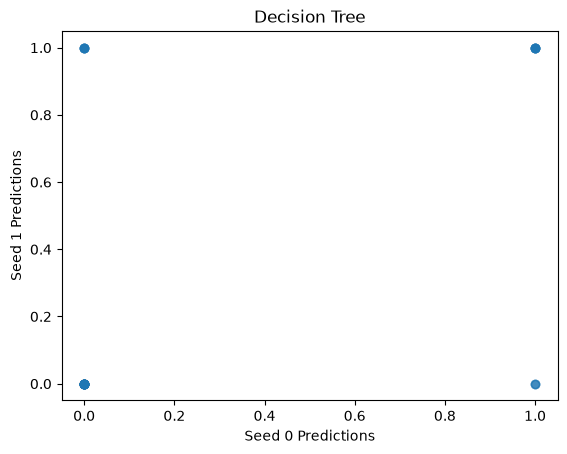

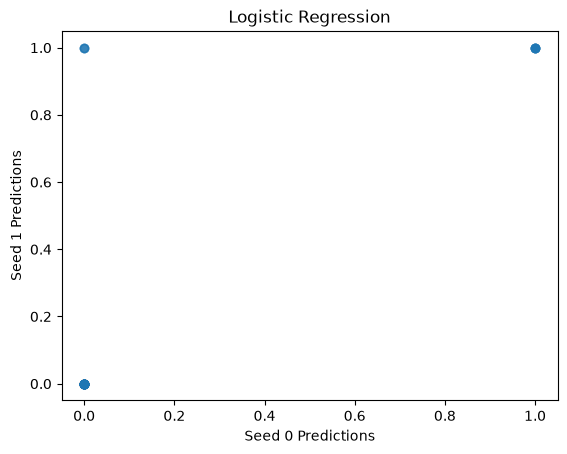

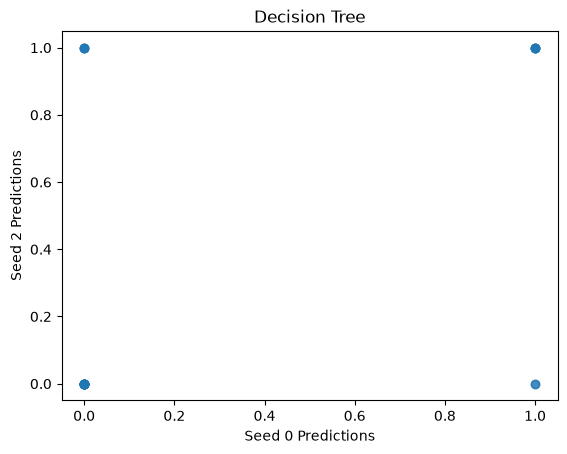

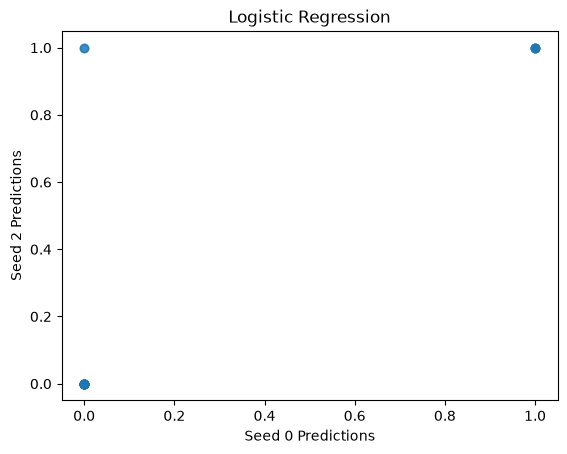

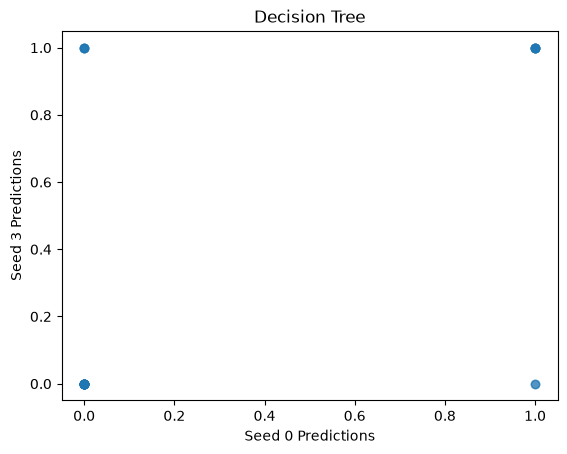

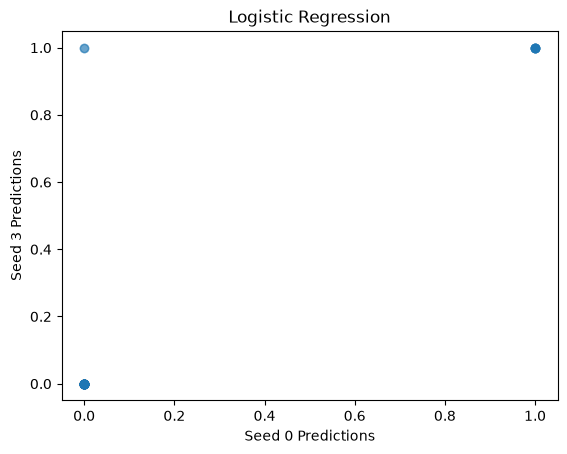

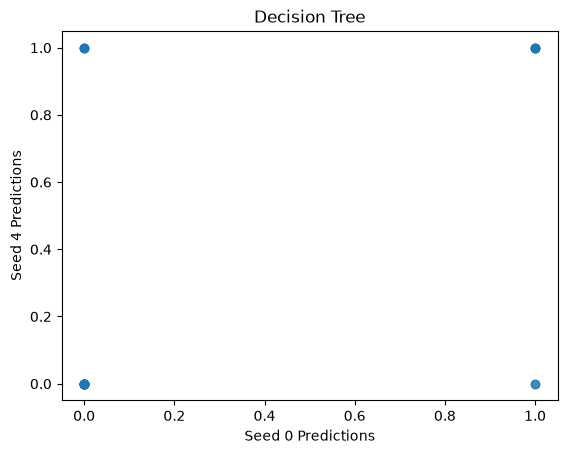

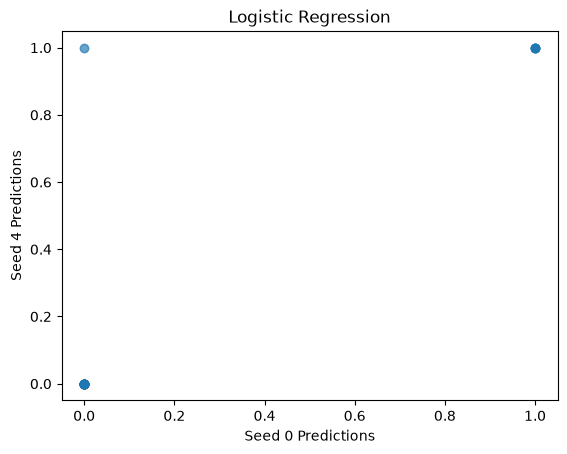

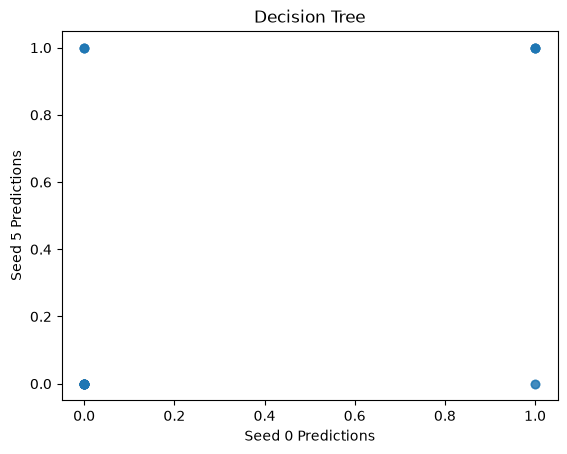

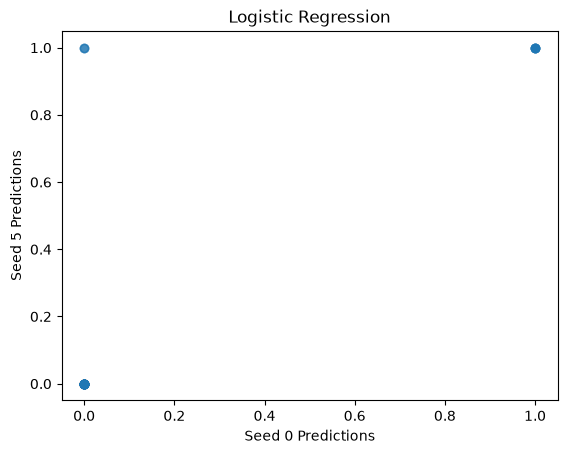

Seed: 1
decision Tree correlation: 0.4305875564144617
logistic regression correlation: 0.7637626158259728
Seed: 2
decision Tree correlation: 0.4563051891067317
logistic regression correlation: 0.7952062255644577
Seed: 3
decision Tree correlation: 0.5311093184684911
logistic regression correlation: 0.8660254037844385
Seed: 4
decision Tree correlation: 0.45630518910673185
logistic regression correlation: 0.8660254037844383
Seed: 5
decision Tree correlation: 0.4563051891067317
logistic regression correlation: 0.7952062255644576
Seed: 1
decision tree intercept: 0.2619047619047619
decision tree slope: 0.46031746031746035
decision tree r2: 0.18540564373897717
logistic regression intercept: 0.12500000000000006
logistic regression slope: 0.8749999999999996
logistic regression r2: 0.5833333333333333
Seed: 2
decision tree intercept: 0.2380952380952381
decision tree slope: 0.4841269841269842
decision tree r2: 0.20821442560573045
logistic regression intercept: 0.10416666666666671
logistic regressi

In [28]:
#  fal

#4a
df_train, df_test = traintest(df, seed=0)

for i in range(5):

    plt.scatter(tree0.predict(df_test[tree0.feature_names_in_]), tree_list[i].predict(df_test[tree0.feature_names_in_]), alpha=0.3)
    plt.xlabel("Seed 0 Predictions")
    plt.ylabel("Seed " + str(i+1) + " Predictions")
    plt.title("Decision Tree")
    plt.show()

    plt.scatter(linear0.predict(df_test[linear0.feature_names_in_]), linear_list[i].predict(df_test[linear0.feature_names_in_]), alpha=0.3)
    plt.xlabel("Seed 0 Predictions")
    plt.ylabel("Seed " + str(i+1) + " Predictions")
    plt.title("Logistic Regression")
    plt.show()

# predictions appear reasonably similar but there is a lot of overlap so visually clear similarity cannot be determined.

#4b
for i in range(5):

    print("Seed:", i+1)
    tree_corr = np.corrcoef(tree0.predict(df_test[tree0.feature_names_in_]), tree_list[i].predict(df_test[tree0.feature_names_in_]))[0, 1]
    print("decision Tree correlation:", tree_corr)

    linear_corr = np.corrcoef(
        linear0.predict(df_test[linear0.feature_names_in_]),
        linear_list[i].predict(df_test[linear0.feature_names_in_]))[0, 1]

    print("logistic regression correlation:", linear_corr)

# the decision trees are correalated but not highly with vallues around 0.4 and 0.5. the logistic trees are more correalated with values 
# around .7 and .8.


#4c
from sklearn.linear_model import LinearRegression

for i in range(5):

    print("Seed:", i+1)

    # decision tree

    tree_reg = LinearRegression().fit(tree0.predict(df_test[tree0.feature_names_in_]).reshape(-1, 1),tree_list[i].predict(df_test[tree0.feature_names_in_]))

    print("decision tree intercept:", tree_reg.intercept_)
    print("decision tree slope:", tree_reg.coef_[0])
    print("decision tree r2:", tree_reg.score(

    tree0.predict(df_test[tree0.feature_names_in_]).reshape(-1, 1), tree_list[i].predict(df_test[tree0.feature_names_in_])))

    # logistic regression

    linear_reg = LinearRegression().fit(linear0.predict(df_test[linear0.feature_names_in_]).reshape(-1, 1), linear_list[i].predict(df_test[linear0.feature_names_in_]))

    print("logistic regression intercept:", linear_reg.intercept_)
    print("logistic regression slope:", linear_reg.coef_[0])
    print("logistic regression r2:", linear_reg.score(

    linear0.predict(df_test[linear0.feature_names_in_]).reshape(-1, 1), linear_list[i].predict(df_test[linear0.feature_names_in_])))

# the decision trees have intercepts farther from 0 and slopes farther from 1 with 
# low r2 values around .1 and .2. logistic regression has intercepts
# closer to 0 and slopes closer to 1 with higher r2 values around .5 and .6.
# neither is perfectly stable, but logistic regression is more consistent
# across the different seeds

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?


The linear models do have similar coefficients (i.e. logistic regression intercept, logisitc regression slope) and predictions across train/test splits. The trees show some consistencies but are overall less similar than the linear models.

6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

True. Although the trees have relatively high variability in coefficients, the predictions and accuracy statistics are quite similar.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 0e2625e
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. Provide a concise, numbered list of changes you recommend I make to these answers.
2. "Use predicted probabilities, not hard labels, in Q4. .predict() returns 0/1, so the scatterplots, correlations and regressions are on binary data. Switch to predict_proba(...)[:, 1] for both models and redo 4a–4c." How do I apply this change?

### *AI-proposed changes


1. Use predicted probabilities, not hard labels, in Q4. .predict() returns 0/1, so the scatterplots, correlations and regressions are on binary data. Switch to predict_proba(...)[:, 1] for both models and redo 4a–4c.
2. Store predictions and fix the splits. modeling never returns the test predictions, and Q4 re-splits and re-predicts in every loop. Save the predictions per seed. Also state that Q4 evaluates all models on seed 0’s test set, which overlaps other seeds’ training data and inflates agreement.
3. Fix traintest. It splits the global df instead of input_df. Use input_df, and add stratify=y given the class imbalance.
4. Q3 doesn’t support its claim. You say the coefficients vary a lot but only printed tree feature importances. Print linear_list[i].coef_ across seeds, tabulate them next to the tree importances, and quantify the spread. For trees, say time is stable (~0.42–0.58) while features like ejection_fraction (0.04–0.19) shift.
5. Correct the terminology and Q5. Trees have feature importances, not coefficients. The intercept and slope in 4c describe the prediction-vs-prediction regression, not the logistic coefficients. Q5 should discuss model coefficients and prediction agreement separately, for both model types.
6. Q6 contradicts your results. You answer “True,” but tree predictions have r≈0.45, R²≈0.2 and slope≈0.5 against seed 0. Similar accuracy doesn’t mean similar predictions. Redo the answer after switching to probabilities (fix 1), and likely qualify it: mostly true for logistic regression, weaker for trees.
7. Make the 4b/4c interpretations match the output. Cite the actual ranges (tree r 0.43–0.53, logistic 0.76–0.87). Your R² summaries are off: trees are 0.19–0.28 and logistic 0.58–0.75. Confirm the 4c output covers all five seeds, since it’s cut off at seed 4. Improve 4a with a y=x line, shared axes, and one subplot figure per model type.
8. Strengthen Q1 cleaning. “Looks clean” isn’t evidence. Add info(), isna().sum(), describe() and a duplicate check. Justify keeping time (possible leakage when predicting death).
9. Acknowledge the unregularized tree. With no max_depth or min_samples_leaf, the tree overfits, which exaggerates instability. Mention it or test a depth-limited tree.
10. Minor cleanup. Define seeds once, call it logistic regression consistently, remove unused variables and no-op crosstab calls, and fix typos (“correalated”, “vallues”).

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Predicted values should be continuous. |
| 2 | Reject | This way would be more efficient, but for our dataset size, the difference is negligible |
| 3 | Accept | Fix traintest function to use proper input |
| 4 | Modify | Show linear model coefficients |
| 5 | Accept | "Feature importance" rather than "coefficients" refer to tree model values |
| 6 | Accept | Fix answer to represent results |
| 7 | Accept | Fix R^2 values to correct values |
| 8 | Accept | Add additional EDA |
| 9 | Modify | Add min_samples_leaf = 5 to the decision tree classifier because dataset is large |
| 10 | Modify | Fix typos and other small errors |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

1. Check out the data set `heart_failure` and appropriately clean it.


In [30]:
# Your Phase 1 solution to the problem goes here.
# Micaiah
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_DIR = Path("data/heart_failure")
df_dirty = pd.read_csv(DATA_DIR / "heart_failure_clinical_records_dataset.csv")
df_dirty.head()

# Dataset looks clean and all columns look relevant.
# Clean df will be df
df = df_dirty
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [46]:
df.isna().sum()

age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

In [47]:
df.describe()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.000000,299.00000,299.000000,299.000000,299.00000,299.000000,299.00000
mean,60.833893,0.431438,581.839465,0.418060,38.083612,0.351171,263358.029264,1.39388,136.625418,0.648829,0.32107,130.260870,0.32107
std,11.894809,0.496107,970.287881,0.494067,11.834841,0.478136,97804.236869,1.03451,4.412477,0.478136,0.46767,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,25100.000000,0.50000,113.000000,0.000000,0.00000,4.000000,0.00000
25%,51.000000,0.000000,116.500000,0.000000,30.000000,0.000000,212500.000000,0.90000,134.000000,0.000000,0.00000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,262000.000000,1.10000,137.000000,1.000000,0.00000,115.000000,0.00000
75%,70.000000,1.000000,582.000000,1.000000,45.000000,1.000000,303500.000000,1.40000,140.000000,1.000000,1.00000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.40000,148.000000,1.000000,1.00000,285.000000,1.00000


2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.


In [54]:
# Micaiah
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn import metrics
seed = 0

# Define a function to train-test split
def traintest(input_df, seed):
    df_train, df_test = train_test_split(input_df, test_size=0.2, random_state=seed)
    print(df_train.shape, df_test.shape)
    return(df_train, df_test)


def modeling(df, seed):
    print("seed: ", seed)

    # Implement split
    [df_train, df_test] = traintest(df, seed=seed)


    # Defining what features we're interested in
    features = ['age',	'anaemia',	'creatinine_phosphokinase',	'diabetes',	'ejection_fraction',	'high_blood_pressure',	'platelets',	'serum_creatinine',	'serum_sodium',	'sex',	'smoking',	'time']
    classes = ['Alive', 'Dead']

    df_train.head()

    # Defining the x and y values for training and testing
    y_train = df_train["DEATH_EVENT"]
    x_train = df_train[features]

    y_test = df_test["DEATH_EVENT"]
    x_test = df_test[features]

    y_ = df["DEATH_EVENT"]
    x_ = df[features]


    # Implement a decision tree classifier
    tree = DecisionTreeClassifier(random_state = seed, min_samples_leaf=5).fit(x_train, y_train)
    y_hat_tree = tree.predict(x_test)

    pd.crosstab(y_test, y_hat_tree,
                rownames=["Actual"], colnames=["Predicted"])

    # plt.figure(figsize = (20, 20), dpi =300)
    # plot_tree(tree, feature_names = features, class_names = classes)
    tree_accuracy = metrics.accuracy_score(y_test, y_hat_tree)
    print("Decision Tree Accuracy:",metrics.accuracy_score(y_test, y_hat_tree))


    # Implement a Linear Regression
    linear = LogisticRegression(random_state=seed, max_iter=10000).fit(x_train, y_train)
    y_hat_linear = linear.predict(x_test)

    pd.crosstab(y_test, y_hat_linear,
                rownames=["Actual"], colnames=["Predicted"])

    linear_accuracy = metrics.accuracy_score(y_test, y_hat_linear)
    print("Logistic Regression Accuracy:",metrics.accuracy_score(y_test, y_hat_linear))

    # Return
    return(tree, linear, tree_accuracy, linear_accuracy)

# Create the model with the seed 0
[tree0, linear0, tree0_accuracy, linear0_accuracy] = modeling(df, seed=0)

seed:  0
(239, 13) (60, 13)
Decision Tree Accuracy: 0.8166666666666667
Logistic Regression Accuracy: 0.7833333333333333


3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

In [55]:
# Micaiah

# Initialize empty lists
tree_list = []
linear_list = []
tree_accuracy_list = []
linear_accuracy_list = []

# Iterate and append (not super efficient but whatever)
for i in range(1, 6):
    [tree_placeholder, linear_placeholder, tree_accuracy_placeholder, linear_accuracy_placeholder] = modeling(df, seed=i)
    tree_list.append(tree_placeholder)
    linear_list.append(linear_placeholder)
    tree_accuracy_list.append(tree_accuracy_placeholder)
    linear_accuracy_list.append(linear_accuracy_placeholder)

seed:  1
(239, 13) (60, 13)
Decision Tree Accuracy: 0.85
Logistic Regression Accuracy: 0.8833333333333333
seed:  2
(239, 13) (60, 13)
Decision Tree Accuracy: 0.8333333333333334
Logistic Regression Accuracy: 0.8666666666666667
seed:  3
(239, 13) (60, 13)
Decision Tree Accuracy: 0.8333333333333334
Logistic Regression Accuracy: 0.8166666666666667
seed:  4
(239, 13) (60, 13)
Decision Tree Accuracy: 0.8333333333333334
Logistic Regression Accuracy: 0.8333333333333334
seed:  5
(239, 13) (60, 13)
Decision Tree Accuracy: 0.7833333333333333
Logistic Regression Accuracy: 0.85


In [56]:
tree_list[0].feature_importances_

array([0.01647227, 0.        , 0.01625614, 0.        , 0.09526776,
       0.        , 0.05659788, 0.1382811 , 0.05551304, 0.        ,
       0.        , 0.62161181])

In [57]:
tree_list[1].feature_importances_

array([0.05646798, 0.        , 0.02474243, 0.        , 0.09663005,
       0.        , 0.07721331, 0.14973495, 0.05524065, 0.        ,
       0.        , 0.53997064])

In [58]:
tree_list[2].feature_importances_

array([0.07714492, 0.        , 0.02724531, 0.        , 0.10470046,
       0.        , 0.01178738, 0.12708572, 0.        , 0.        ,
       0.        , 0.65203621])

In [59]:
tree_list[3].feature_importances_

array([0.02801154, 0.        , 0.02002905, 0.        , 0.06627927,
       0.        , 0.07008034, 0.14493888, 0.04664155, 0.        ,
       0.        , 0.62401937])

In [60]:
tree_list[4].feature_importances_

array([0.04735915, 0.        , 0.04876228, 0.        , 0.13432441,
       0.        , 0.03470023, 0.00373757, 0.04588155, 0.05200833,
       0.        , 0.63322647])

There is quite significant variability in the feature importances. For instance, the coefficient for the ejection fraction varies from 0.04 to 0.19.

4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?



(239, 13) (60, 13)


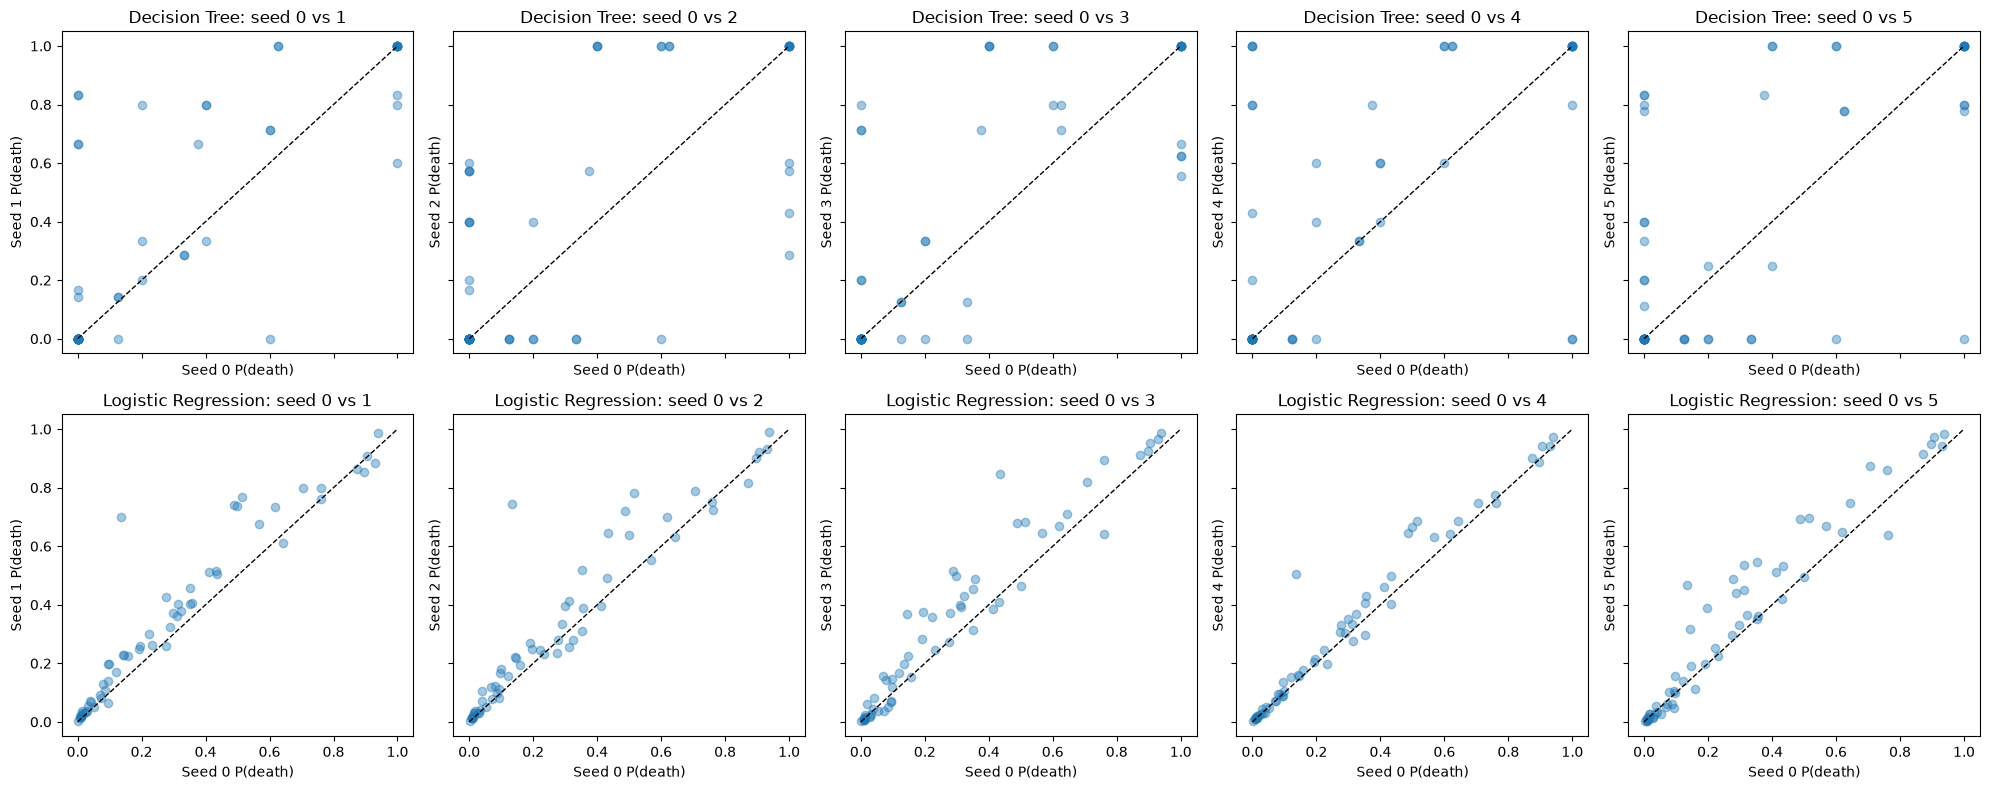

In [61]:
df_train, df_test = traintest(df, seed=0)
X_test = df_test[tree0.feature_names_in_]

p_tree0 = tree0.predict_proba(X_test)[:, 1]
p_lin0  = linear0.predict_proba(X_test)[:, 1]
p_tree  = [m.predict_proba(X_test)[:, 1] for m in tree_list]
p_lin   = [m.predict_proba(X_test)[:, 1] for m in linear_list]

fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=True, sharey=True)
for i in range(5):
    for row, (name, base, alt) in enumerate([
        ("Decision Tree", p_tree0, p_tree[i]),
        ("Logistic Regression", p_lin0, p_lin[i]),
    ]):
        ax = axes[row, i]
        ax.scatter(base, alt, alpha=0.4)
        ax.plot([0, 1], [0, 1], "k--", lw=1)
        ax.set_title(f"{name}: seed 0 vs {i+1}")
        ax.set_xlabel("Seed 0 P(death)")
        ax.set_ylabel(f"Seed {i+1} P(death)")
plt.tight_layout()
plt.show()

The scatterplots do look pretty similar for logistic regression. There are major differences for the decision tree.

In [62]:
rows = []
for i in range(5):
    for name, base, alt in [("Tree", p_tree0, p_tree[i]),
                            ("Logistic", p_lin0, p_lin[i])]:
        reg = LinearRegression().fit(base.reshape(-1, 1), alt)
        rows.append({
            "seed": i + 1,
            "model": name,
            "corr": np.corrcoef(base, alt)[0, 1],
            "intercept": reg.intercept_,
            "slope": reg.coef_[0],
            "R2": reg.score(base.reshape(-1, 1), alt),
        })
results = pd.DataFrame(rows).round(3)
results

,seed,model,corr,intercept,slope,R2
0,1,Tree,0.806,0.117,0.853,0.649
1,1,Logistic,0.953,0.056,1.010,0.908
2,2,Tree,0.722,0.124,0.771,0.521
3,2,Logistic,0.944,0.046,0.999,0.891
4,3,Tree,0.799,0.105,0.863,0.639
5,3,Logistic,0.962,0.037,1.056,0.925
6,4,Tree,0.646,0.170,0.724,0.417
7,4,Logistic,0.979,0.018,1.034,0.959
8,5,Tree,0.692,0.135,0.755,0.479
9,5,Logistic,0.965,0.029,1.068,0.931


The tree models are moderately highly correlated, with more variation in correlation. The logistic regression models are highly correlated, and the correlation has low variability.

In [63]:
linear_list[0].coef_

array([[ 4.19059285e-02, -1.01823787e-01,  2.07057796e-04,
         4.51280020e-01, -6.94637564e-02, -2.43035629e-01,
        -2.54977177e-06,  7.54638577e-01,  7.21714908e-03,
        -2.56812572e-01, -8.80008807e-02, -1.94147727e-02]])

In [64]:
linear_list[1].coef_

array([[ 5.00421897e-02,  3.98832340e-02,  4.08574669e-04,
         1.04081900e-01, -6.81283104e-02, -1.24195723e-01,
        -1.31125472e-06,  7.52395235e-01,  9.47664548e-04,
        -4.15235526e-01, -1.57522853e-01, -1.88413687e-02]])

In [65]:
linear_list[2].coef_

array([[ 7.07992037e-02, -3.00805886e-01,  5.83751302e-04,
         8.33309624e-02, -8.09881890e-02, -3.42225291e-01,
        -8.11084413e-07,  6.03770642e-01, -3.29555979e-03,
        -2.95070050e-01,  1.94558492e-01, -2.09835275e-02]])

In [66]:
linear_list[3].coef_

array([[ 5.45593591e-02,  7.56967685e-02,  2.23829820e-04,
         5.13741654e-01, -7.81417262e-02, -2.75978573e-02,
        -8.64629700e-07,  7.35855874e-01, -1.39813969e-03,
        -1.51951783e-01,  1.41005641e-03, -2.01744448e-02]])

In [67]:
linear_list[4].coef_

array([[ 6.86896982e-02, -3.22277605e-01,  2.61393295e-04,
         1.57987598e-01, -6.84398129e-02, -1.82127194e-01,
        -2.58407056e-06,  7.00670288e-01, -7.80762311e-04,
        -4.80264974e-01,  3.61635578e-01, -2.30900885e-02]])

The tree R^2 values are consistently lower than the logistic regression R^2 values.

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?


The linear models do have similar coefficients (i.e. logistic regression intercept, logisitc regression slope) and predictions across train/test splits. The trees show some consistencies but are overall less similar than the linear models.

6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

False for trees. The tree models have quite different predictions (4a tree scatterplots). However, the logistic regression models generate quite similar results.

### *Reflection on AI assistance
In your own words without generative AI.

The suggested changes from AI were quite helpful in identifying errors in the code and in responses to the questions. The most significant change that AI recommended was to use continuous, predicted probabilities as the predicted outcomes rather than just a binary 0/1 classification. This change allowed us to properly understand that the tree models had significant variability in prediction outcomes, while the linear regression models were fairly consistent. These patterns were not visible in the scatterplots in Question 4 prior to applying this change. AI also suggested some changes that did change the results but did make the code more applicable to other situations. For instance, we passed the wrong variable name in the testtrain test function, and the function only worked due to us passing the same dataframe name in each time the function was used. Another helpful suggestion was to use min_samples_leaf so that the trees would not overfit. We verified that we should apply this suggested change by comparing to the slides from class, and we found that we should use min_samples_leaf in this case.